# **5. Validação por classificação reversa (texto → rótulos)**

O notebook `2` construiu a taxonomia multirrótulo a partir de **regras**: código disciplinar oficial mais padrões lexicais explícitos sobre o texto normalizado. Isso é auditável, mas não prova que as categorias são semanticamente coerentes no texto — só prova que as regras casam com os padrões que foram escritos para elas.

Este notebook faz o caminho inverso. Um classificador supervisionado que só vê o **texto** (sem código oficial, sem as regras) tenta recuperar o mesmo rótulo multirrótulo. A validação é sempre fora da amostra (`k`-fold estratificado para multirrótulo), então a acurácia reportada é a de um texto nunca visto pelo modelo que o classificou. Alta recuperação valida que os rótulos têm sinal lexical real; falhas concentradas numa categoria apontam sobreposição semântica, ambiguidade ou poucos exemplos — a mesma fila de auditoria do notebook `2`, agora vista pelo ângulo do modelo em vez do ângulo da regra.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

INPUT_DIR = ROOT / "data" / "processed" / "keyword_tags"
TEXTS_PATH = INPUT_DIR / "unique_text_tags.csv"
MANIFEST_PATH = INPUT_DIR / "run_manifest.json"

OUTPUT_DIR = ROOT / "data" / "processed" / "classification_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIZ_DIR = ROOT / "viz"
VIZ_DIR.mkdir(parents=True, exist_ok=True)

## **1. Dados de referência**

`unique_text_tags.csv` traz um texto único por linha (já sem acento/stopword, o mesmo texto que as regras do notebook `2` avaliam) com as 17 colunas booleanas de `SEMANTIC_TAGS`. `run_manifest.json` carrega o rótulo e a família de cada categoria — lidos daqui, não redigitados, para não duplicar a fonte da verdade do notebook `2`. `NAO_CLASSIFICADA` fica de fora do alvo: hoje a cobertura das regras é de 100% dos textos, então essa coluna é sempre `False` e não carrega sinal para o modelo aprender.

In [2]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
SEMANTIC_TAGS = manifest["tags"]
TAG_LABELS = {tag: spec["label"] for tag, spec in manifest["taxonomy"].items()}
TAG_FAMILIES = {tag: spec["family"] for tag, spec in manifest["taxonomy"].items()}

texts = pd.read_csv(TEXTS_PATH)
required_columns = {"reason_key", "reason", "event_count", *SEMANTIC_TAGS}
missing_columns = sorted(required_columns.difference(texts.columns))
if missing_columns:
    raise ValueError(f"Colunas ausentes em {TEXTS_PATH.name}: {missing_columns}")

X_text = texts["reason"].to_numpy()
Y = texts[SEMANTIC_TAGS].to_numpy(dtype=bool)

display(
    pd.DataFrame(
        {
            "metric": ["textos únicos", "categorias", "eventos representados", "cardinalidade média"],
            "value": [len(texts), len(SEMANTIC_TAGS), int(texts["event_count"].sum()), round(Y.sum(axis=1).mean(), 2)],
        }
    )
)

support = pd.DataFrame(
    {
        "tag": SEMANTIC_TAGS,
        "label": [TAG_LABELS[t] for t in SEMANTIC_TAGS],
        "family": [TAG_FAMILIES[t] for t in SEMANTIC_TAGS],
        "n_textos": Y.sum(axis=0),
        "n_eventos": [int(texts.loc[texts[t], "event_count"].sum()) for t in SEMANTIC_TAGS],
    }
).sort_values("n_eventos", ascending=False).reset_index(drop=True)
display(support)

,metric,value
0,textos únicos,4188.00
1,categorias,17.00
2,eventos representados,13964.00
3,cardinalidade média,1.29


,tag,label,family,n_textos,n_eventos
0,ACAO_TEMERARIA,Ação temerária,Faltas e infrações de jogo,925,5977
1,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,Comportamento e disciplina,906,2849
2,FALTA_TATICA,Impedir ataque promissor,Faltas e infrações de jogo,486,2238
3,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,Comportamento e disciplina,826,1670
4,RETARDAR_REINICIO,Retardar o jogo,Infrações procedimentais,431,1124
5,CONFRONTO_TUMULTO,Confronto ou tumulto,Comportamento e disciplina,404,692
6,USO_IRREGULAR_BRACO,Uso irregular do braço,Faltas e infrações de jogo,191,362
7,COMEMORACAO_IRREGULAR,Comemoração irregular,Infrações procedimentais,136,226
8,LINGUAGEM_OFENSIVA,Ofensa verbal ou gestual,Comportamento e disciplina,223,226
9,MAO_ANTIDESPORTIVA,Mão na bola,Faltas e infrações de jogo,64,207


## **2. Validação cruzada multirrótulo estratificada**

O suporte por categoria é bem desbalanceado (de 47 textos em `SIMULACAO` a 918 em `ACAO_TEMERARIA`) e 22,7% dos textos carregam mais de um rótulo. Um split aleatório simples pode isolar quase todos os exemplos de uma categoria rara num único fold. `MultilabelStratifiedKFold` ([iterative-stratification](https://github.com/trent-b/iterative-stratification), já presente em `requirements.txt`) distribui as combinações de rótulos entre os `k` folds preservando a proporção de cada categoria — inclusive as raras.

In [3]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

N_FOLDS = 5
SEED = 42

mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_assignment = np.full(len(texts), -1, dtype=int)
for fold_id, (_, test_index) in enumerate(mskf.split(X_text, Y)):
    fold_assignment[test_index] = fold_id
texts["fold"] = fold_assignment

### Verificação de sanidade da divisão em folds

In [4]:
assert (fold_assignment >= 0).all(), "todo texto deve cair em exatamente um fold"
assert np.bincount(fold_assignment, minlength=N_FOLDS).sum() == len(texts), "os folds devem cobrir todos os textos"
assert texts["reason"].duplicated().sum() == 0, "reason não deveria ter duplicatas (mesma checagem do notebook 2)"

fold_tag_support = pd.DataFrame(
    {fold_id: Y[fold_assignment == fold_id].sum(axis=0) for fold_id in range(N_FOLDS)},
    index=SEMANTIC_TAGS,
)
empty_fold_tags = fold_tag_support.index[(fold_tag_support == 0).any(axis=1)].tolist()
if empty_fold_tags:
    print(f"aviso: categorias sem exemplo positivo em algum fold: {empty_fold_tags}")
else:
    print(f"{N_FOLDS} folds, todas as {len(SEMANTIC_TAGS)} categorias têm >=1 exemplo positivo em cada fold")
display(fold_tag_support)

5 folds, todas as 17 categorias têm >=1 exemplo positivo em cada fold


,0,1,2,3,4
ACAO_TEMERARIA,185,185,185,185,185
FALTA_TATICA,97,97,97,98,97
IMPEDIR_OPORTUNIDADE_GOL,21,21,20,21,21
JOGO_BRUSCO_GRAVE,38,38,37,38,38
MAO_ANTIDESPORTIVA,13,13,13,13,12
USO_IRREGULAR_BRACO,38,39,38,38,38
INFRACAO_PERSISTENTE,15,15,16,15,16
RECLAMAR_ARBITRAGEM,181,181,181,181,182
CONDUTA_VIOLENTA,39,39,39,39,39
LINGUAGEM_OFENSIVA,45,45,44,45,44


## **3. Modelo: TF-IDF + regressão logística por rótulo**

Assim como o notebook `2` preferiu regras auditáveis a embeddings, este notebook usa um modelo linear transparente em vez de uma rede neural: TF-IDF de palavras (1,2-grama, captura expressões como `"área técnica"`) combinado com TF-IDF de caracteres (3,5-grama, absorve variações e erros de digitação do texto informal das súmulas), alimentando uma regressão logística **um-contra-todos** por categoria (`class_weight="balanced"` compensa o desbalanceamento de suporte). Cada fold ajusta os vetorizadores e o modelo só no treino; a predição de probabilidade no fold de teste é acumulada numa matriz **fora da amostra** (`oof_proba`) — nenhuma métrica adiante usa um texto que o modelo que o classificou já tenha visto.

In [5]:
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier


def build_design_matrix(train_texts, eval_texts):
    word_vectorizer = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2)
    char_vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2)
    word_train = word_vectorizer.fit_transform(train_texts)
    char_train = char_vectorizer.fit_transform(train_texts)
    word_eval = word_vectorizer.transform(eval_texts)
    char_eval = char_vectorizer.transform(eval_texts)
    return hstack([word_train, char_train]).tocsr(), hstack([word_eval, char_eval]).tocsr()


oof_proba = np.zeros((len(texts), len(SEMANTIC_TAGS)))
for fold_id in range(N_FOLDS):
    train_mask = fold_assignment != fold_id
    test_mask = fold_assignment == fold_id
    X_train, X_test = build_design_matrix(X_text[train_mask], X_text[test_mask])
    model = OneVsRestClassifier(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    )
    model.fit(X_train, Y[train_mask])
    oof_proba[test_mask] = model.predict_proba(X_test)

THRESHOLD = 0.5
oof_pred = oof_proba >= THRESHOLD

oof_df = texts[["reason_key", "reason", "event_count", "fold"]].copy()
for i, tag in enumerate(SEMANTIC_TAGS):
    oof_df[f"true_{tag}"] = Y[:, i]
    oof_df[f"proba_{tag}"] = oof_proba[:, i]
    oof_df[f"pred_{tag}"] = oof_pred[:, i]
oof_df.to_csv(OUTPUT_DIR / "oof_predictions.csv", index=False)
print(f"predições fora da amostra salvas para {len(oof_df)} textos")

predições fora da amostra salvas para 4188 textos


## **4. Métricas de recuperação por rótulo**

Precisão, recall, F1 (no limiar de 0,5), ROC-AUC e PR-AUC por categoria, ordenados pelo mesmo critério de `n_eventos` usado em `tag_frequency.csv` no notebook `2`. Categorias com poucos exemplos (`SIMULACAO`, `ENTRADA_SAIDA_CAMPO`, `MAO_ANTIDESPORTIVA`, todas com menos de 65 textos) devem ter métricas mais ruidosas — limitação declarada, não escondida.

In [6]:
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score

tag_rows = []
for i, tag in enumerate(SEMANTIC_TAGS):
    y_true, y_pred, y_score = Y[:, i], oof_pred[:, i], oof_proba[:, i]
    has_both_classes = bool(y_true.any() and (~y_true).any())
    tag_rows.append({
        "tag": tag,
        "label": TAG_LABELS[tag],
        "family": TAG_FAMILIES[tag],
        "n_textos": int(y_true.sum()),
        "n_eventos": int(texts.loc[y_true, "event_count"].sum()),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if has_both_classes else np.nan,
        "pr_auc": average_precision_score(y_true, y_score) if has_both_classes else np.nan,
    })

tag_metrics = pd.DataFrame(tag_rows).sort_values("n_eventos", ascending=False).reset_index(drop=True)
tag_metrics.to_csv(OUTPUT_DIR / "tag_recovery_metrics.csv", index=False)
display(tag_metrics.round(3))

,tag,label,family,n_textos,n_eventos,precisao,recall,f1,roc_auc,pr_auc
0,ACAO_TEMERARIA,Ação temerária,Faltas e infrações de jogo,925,5977,0.983,0.960,0.972,0.999,0.996
1,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,Comportamento e disciplina,906,2849,0.947,0.972,0.960,0.996,0.993
2,FALTA_TATICA,Impedir ataque promissor,Faltas e infrações de jogo,486,2238,0.909,0.930,0.920,0.994,0.978
3,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,Comportamento e disciplina,826,1670,0.938,0.898,0.918,0.987,0.972
4,RETARDAR_REINICIO,Retardar o jogo,Infrações procedimentais,431,1124,0.936,0.944,0.940,0.993,0.984
5,CONFRONTO_TUMULTO,Confronto ou tumulto,Comportamento e disciplina,404,692,0.830,0.928,0.876,0.993,0.951
6,USO_IRREGULAR_BRACO,Uso irregular do braço,Faltas e infrações de jogo,191,362,0.625,0.953,0.755,0.994,0.906
7,COMEMORACAO_IRREGULAR,Comemoração irregular,Infrações procedimentais,136,226,0.978,0.978,0.978,0.999,0.992
8,LINGUAGEM_OFENSIVA,Ofensa verbal ou gestual,Comportamento e disciplina,223,226,0.789,0.955,0.864,0.997,0.939
9,MAO_ANTIDESPORTIVA,Mão na bola,Faltas e infrações de jogo,64,207,0.519,0.844,0.643,0.989,0.777


## **5. Métricas globais e peso pela frequência real**

Como no notebook `2` (`textos_com_categoria` vs `eventos_com_categoria`), toda métrica global é reportada duas vezes: sem peso (design da taxonomia — cada texto único vale igual) e ponderada por `event_count` (uso operacional real — poucos textos "padrão" cobrem centenas de eventos). O baseline de comparação prevê sempre a categoria mais frequente por eventos, sozinha, para todo texto — mede o quanto o modelo aprende além de "nada".

In [7]:
from sklearn.metrics import accuracy_score, hamming_loss


def global_metrics(y_true, y_pred, weights):
    return {
        "acuracia_exata": accuracy_score(y_true, y_pred, sample_weight=weights),
        "hamming_loss": hamming_loss(y_true, y_pred, sample_weight=weights),
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0, sample_weight=weights),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0, sample_weight=weights),
    }


weights_uniform = np.ones(len(texts))
weights_events = texts["event_count"].to_numpy(dtype=float)

baseline_tag = tag_metrics.iloc[0]["tag"]
baseline_index = SEMANTIC_TAGS.index(baseline_tag)
baseline_pred = np.zeros_like(Y)
baseline_pred[:, baseline_index] = True

records = []
for model_name, pred in [("modelo", oof_pred), ("baseline_maioria", baseline_pred)]:
    for weight_name, weights in [("texto_unico", weights_uniform), ("ponderado_evento", weights_events)]:
        records.append({"modelo": model_name, "peso": weight_name, **global_metrics(Y, pred, weights)})

global_df = pd.DataFrame(records)
global_df.to_csv(OUTPUT_DIR / "global_metrics.csv", index=False)
display(global_df.round(4))

,modelo,peso,acuracia_exata,hamming_loss,f1_micro,f1_macro
0,modelo,texto_unico,0.7947,0.0145,0.9076,0.8779
1,modelo,ponderado_evento,0.8629,0.0094,0.9320,0.8699
2,baseline_maioria,texto_unico,0.1614,0.1086,0.1931,0.0213
3,baseline_maioria,ponderado_evento,0.3619,0.0781,0.3920,0.0353


## **6. Visualizações**

Mesmo padrão visual usado em `mapper-player-development` e nos projetos de dataviz do Atlas: fundo branco, sem grid, eixos só à esquerda/embaixo, texto em negrito, `dpi=300`, figuras salvas em `viz/` antes de exibidas.

In [8]:
import matplotlib.pyplot as plt

BLUE, RED, GOLD, INK = "#06478f", "#b01f16", "#d97706", "#111111"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Open Sans", "DejaVu Sans", "Arial"]

FAMILY_COLORS = {
    "Faltas e infrações de jogo": BLUE,
    "Comportamento e disciplina": RED,
    "Infrações procedimentais": GOLD,
}


def style_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK)
    ax.grid(False)
    ax.set_title(ax.get_title(), fontweight="bold")
    ax.xaxis.label.set_fontweight("bold"); ax.yaxis.label.set_fontweight("bold")
    for label in [*ax.get_xticklabels(), *ax.get_yticklabels()]: label.set_fontweight("bold")

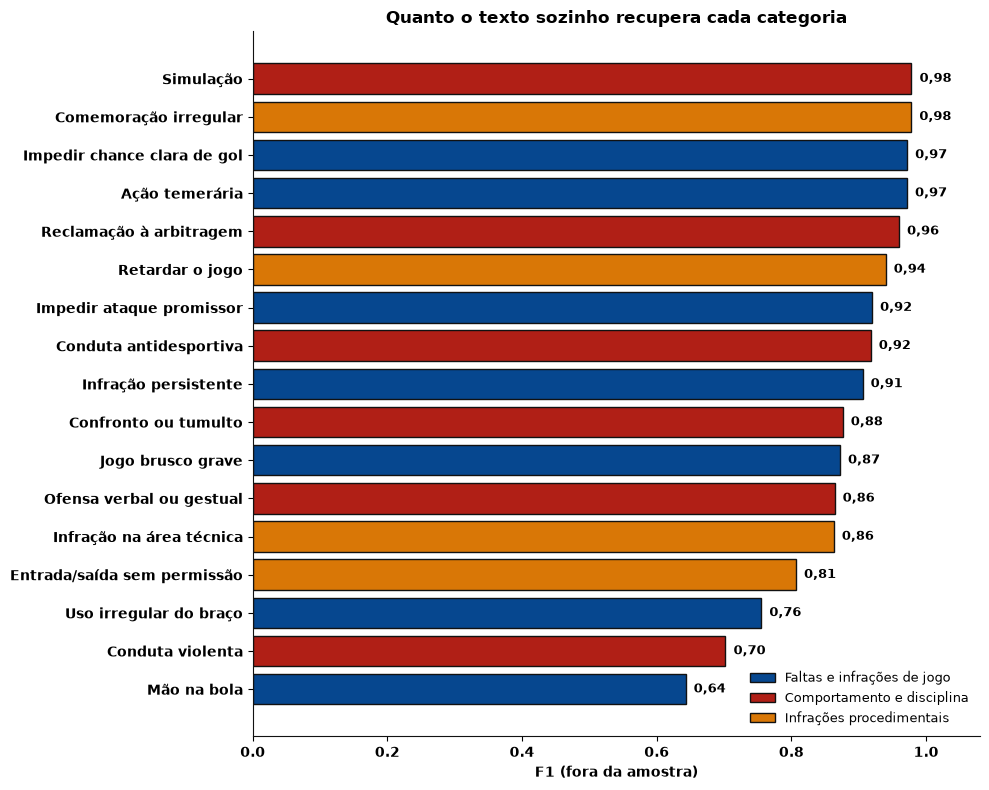

In [9]:
plot_order = tag_metrics.sort_values("f1", ascending=True)
colors = [FAMILY_COLORS[family] for family in plot_order["family"]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_order["label"], plot_order["f1"], color=colors, edgecolor=INK)
for y, value in enumerate(plot_order["f1"]):
    ax.text(value + .012, y, f"{value:.2f}".replace(".", ","), va="center", fontweight="bold", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("F1 (fora da amostra)")
ax.set_title("Quanto o texto sozinho recupera cada categoria")
handles = [plt.Rectangle((0, 0), 1, 1, color=color, ec=INK) for color in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), frameon=False, loc="lower right", fontsize=9)
style_axis(ax)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_01_f1_por_categoria.png", dpi=300, bbox_inches="tight")
plt.show()

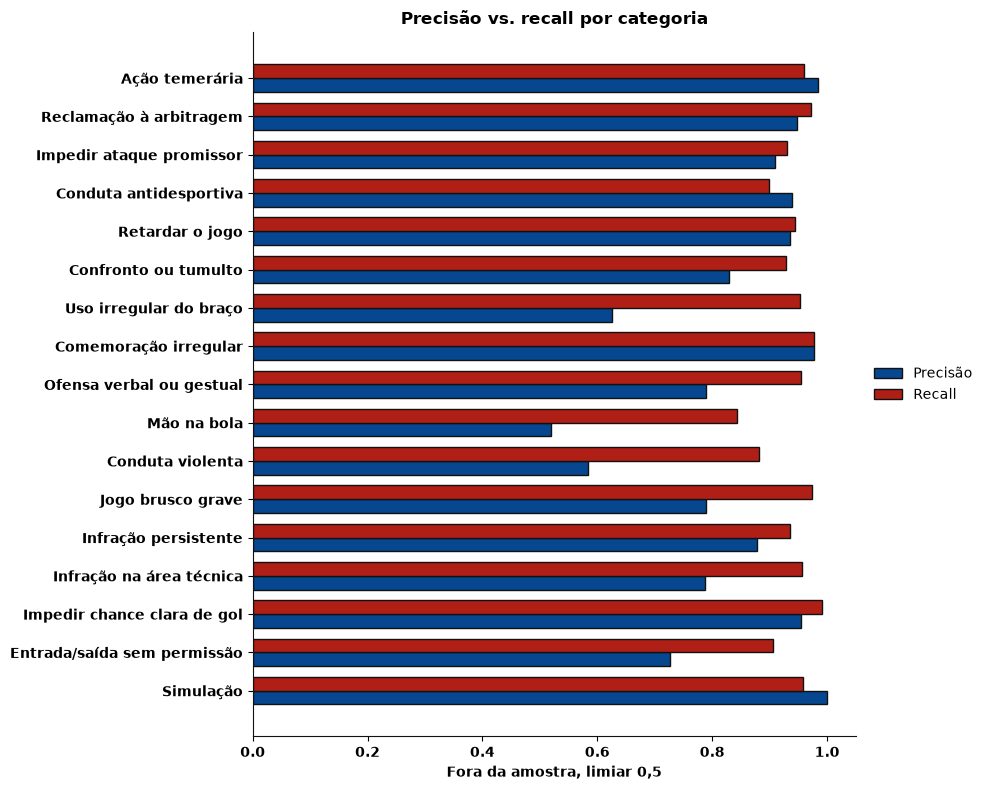

In [10]:
plot_order = tag_metrics.sort_values("n_eventos", ascending=True)
y = np.arange(len(plot_order))
height = 0.36

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(y - height / 2, plot_order["precisao"], height, color=BLUE, edgecolor=INK, label="Precisão")
ax.barh(y + height / 2, plot_order["recall"], height, color=RED, edgecolor=INK, label="Recall")
ax.set_yticks(y)
ax.set_yticklabels(plot_order["label"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Fora da amostra, limiar 0,5")
ax.set_title("Precisão vs. recall por categoria")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
style_axis(ax)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_02_precisao_recall_por_categoria.png", dpi=300, bbox_inches="tight")
plt.show()

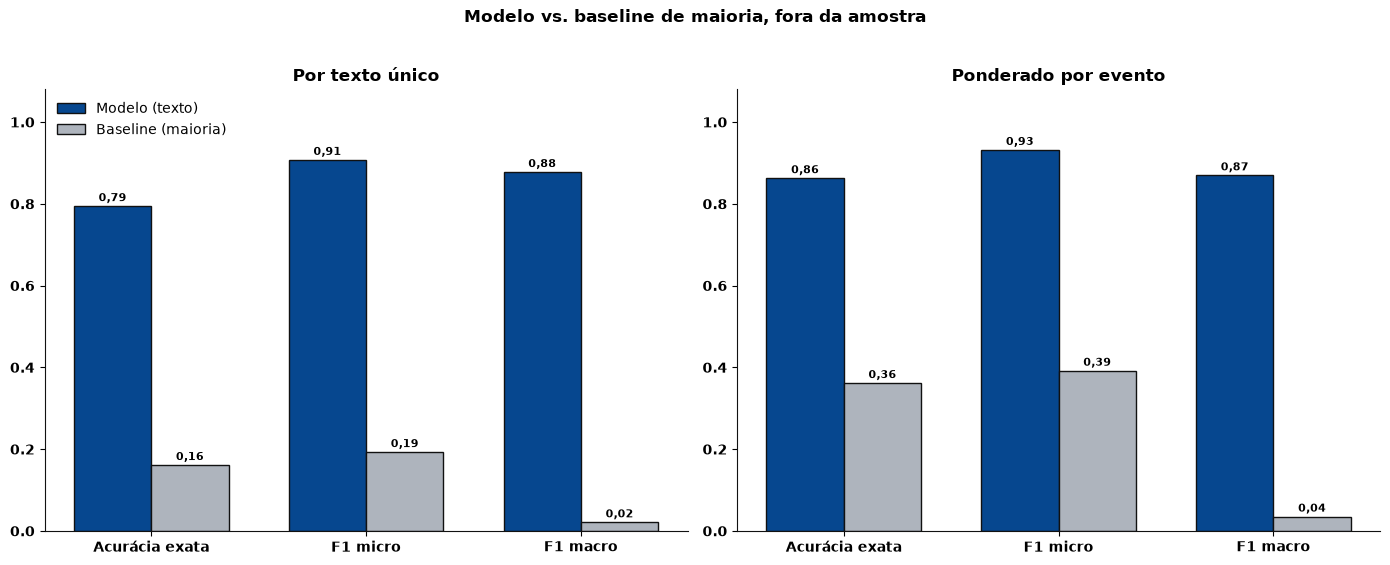

In [11]:
metric_labels = {"acuracia_exata": "Acurácia exata", "f1_micro": "F1 micro", "f1_macro": "F1 macro"}
metrics_to_plot = list(metric_labels)
weight_panels = [("texto_unico", "Por texto único"), ("ponderado_evento", "Ponderado por evento")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (weight_name, weight_title) in zip(axes, weight_panels):
    panel = global_df.loc[global_df["peso"].eq(weight_name)].set_index("modelo")
    x = np.arange(len(metrics_to_plot))
    width = 0.36
    model_bars = ax.bar(x - width / 2, panel.loc["modelo", metrics_to_plot], width,
                         color=BLUE, edgecolor=INK, label="Modelo (texto)")
    baseline_bars = ax.bar(x + width / 2, panel.loc["baseline_maioria", metrics_to_plot], width,
                            color="#aeb4bd", edgecolor=INK, label="Baseline (maioria)")
    for bars in (model_bars, baseline_bars):
        for bar in bars:
            value = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, value + .012, f"{value:.2f}".replace(".", ","),
                    ha="center", fontweight="bold", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([metric_labels[m] for m in metrics_to_plot])
    ax.set_ylim(0, 1.08)
    ax.set_title(weight_title)
    style_axis(ax)
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Modelo vs. baseline de maioria, fora da amostra", fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_03_acuracia_global.png", dpi=300, bbox_inches="tight")
plt.show()

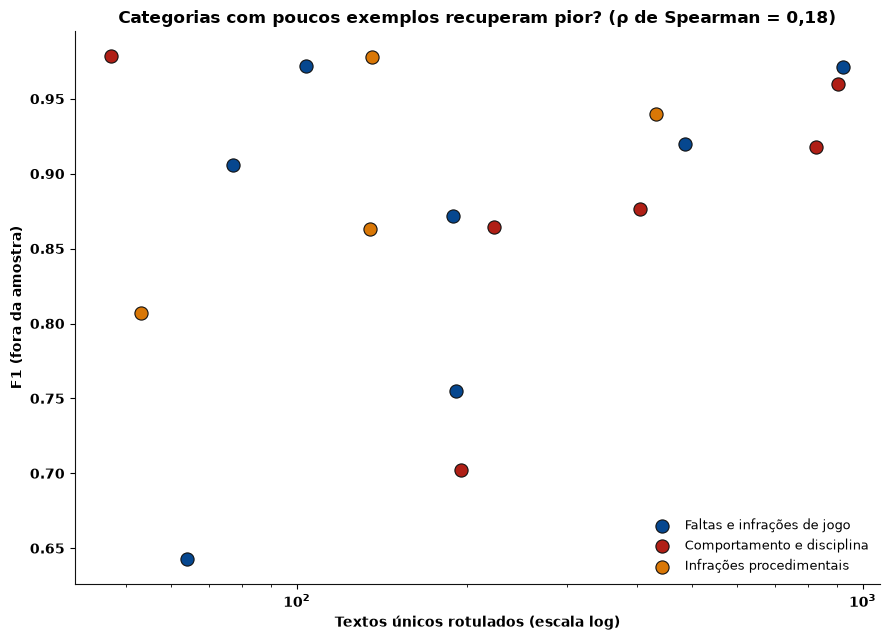

In [12]:
from scipy.stats import spearmanr

rho, _ = spearmanr(tag_metrics["n_textos"], tag_metrics["f1"])

fig, ax = plt.subplots(figsize=(9, 6.5))
for family, color in FAMILY_COLORS.items():
    subset = tag_metrics.loc[tag_metrics["family"].eq(family)]
    ax.scatter(subset["n_textos"], subset["f1"], s=90, facecolors=color, edgecolors=INK,
               linewidths=0.8, label=family, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("Textos únicos rotulados (escala log)")
ax.set_ylabel("F1 (fora da amostra)")
ax.set_title(f"Categorias com poucos exemplos recuperam pior? (ρ de Spearman = {rho:.2f})".replace(".", ","))
ax.legend(frameon=False, loc="lower right", fontsize=9)
style_axis(ax)
fig.tight_layout()
fig.savefig(VIZ_DIR / "5_04_suporte_vs_f1.png", dpi=300, bbox_inches="tight")
plt.show()

## **7. Auditoria de erros**

Falsos positivos e falsos negativos por categoria, na mesma lógica de fila de auditoria de `unclassified_texts.csv` no notebook `2`: quanto maior `event_count`, maior o impacto prático do erro se a categoria fosse decidida só pelo texto.

In [13]:
error_rows = []
for i, tag in enumerate(SEMANTIC_TAGS):
    false_positive = (~Y[:, i]) & oof_pred[:, i]
    false_negative = Y[:, i] & (~oof_pred[:, i])
    for error_type, mask in [("falso_positivo", false_positive), ("falso_negativo", false_negative)]:
        for idx in np.where(mask)[0]:
            error_rows.append({
                "reason_key": texts.iloc[idx]["reason_key"],
                "reason": texts.iloc[idx]["reason"],
                "event_count": int(texts.iloc[idx]["event_count"]),
                "tag": tag,
                "tag_label": TAG_LABELS[tag],
                "error_type": error_type,
                "proba": float(oof_proba[idx, i]),
            })

errors_df = pd.DataFrame(error_rows).sort_values("event_count", ascending=False).reset_index(drop=True)
errors_df.to_csv(OUTPUT_DIR / "misclassified_texts.csv", index=False)
print(f"{len(errors_df)} erros de categoria em {errors_df['reason_key'].nunique()} textos")
display(errors_df.head(30))

1034 erros de categoria em 860 textos


,reason_key,reason,event_count,tag,tag_label,error_type,proba
0,dar entrada temeraria adversario disputa bola,dar entrada temeraria adversario disputa bola,319,RECLAMAR_ARBITRAGEM,Reclamação à arbitragem,falso_negativo,0.001544
1,impedir ataque promissor,impedir ataque promissor,123,MAO_ANTIDESPORTIVA,Mão na bola,falso_negativo,0.279378
2,impedir ataque promissor,impedir ataque promissor,123,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,falso_negativo,0.008493
3,dar entrada temeraria contra adversario disput...,dar entrada temeraria contra adversario disput...,82,FALTA_TATICA,Impedir ataque promissor,falso_negativo,0.009256
4,reclamar forma acintosa contra decisoes arbitr...,reclamar forma acintosa contra decisoes arbitr...,63,RETARDAR_REINICIO,Retardar o jogo,falso_negativo,0.008308
5,segurar adversario mostrando desrespeito jogo,segurar adversario mostrando desrespeito jogo,33,FALTA_TATICA,Impedir ataque promissor,falso_negativo,0.237477
6,cometer falta impedindo ataque promissor,cometer falta impedindo ataque promissor,31,MAO_ANTIDESPORTIVA,Mão na bola,falso_positivo,0.687817
7,desaprovar decisoes arbitragem,desaprovar decisoes arbitragem,28,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,falso_negativo,0.011067
8,tirar camisa comemoracao gol,tirar camisa comemoracao gol,27,CONDUTA_ANTIDESPORTIVA,Conduta antidesportiva,falso_negativo,0.055370
9,segurar adversario forma acintosa,segurar adversario forma acintosa,27,FALTA_TATICA,Impedir ataque promissor,falso_positivo,0.846103


## **8. Exportação**

Registra a configuração do experimento junto das métricas globais, no mesmo padrão de `keyword_tags/run_manifest.json` e `var_usage/run_manifest.json` — para que qualquer resultado citado aqui seja rastreável até a versão do modelo que o produziu.

In [14]:
run_manifest = {
    "generated_at": pd.Timestamp.now().isoformat(),
    "n_texts": len(texts),
    "n_tags": len(SEMANTIC_TAGS),
    "cross_validation": {"strategy": "MultilabelStratifiedKFold", "n_folds": N_FOLDS, "seed": SEED},
    "model": {
        "vectorizers": ["tfidf word (1,2)-grama min_df=2", "tfidf char_wb (3,5)-grama min_df=2"],
        "classifier": "OneVsRestClassifier(LogisticRegression(class_weight='balanced'))",
        "threshold": THRESHOLD,
    },
    "baseline_tag": baseline_tag,
    "global_metrics": global_df.to_dict(orient="records"),
}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("saved", OUTPUT_DIR / "run_manifest.json")

saved /Users/gabrielcarbinatto/Documents/GitHub/cbf-match-report-analysis/data/processed/classification_validation/run_manifest.json
